We'll expand the characterization of the baseline microbiome in this notebook to cover all our potential metrics and 

In [1]:
import itertools as it
import os
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import biom
import numpy as np
import pandas as pd
import scipy
import skbio
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.diversity.actions as q2_div
import qiime2.plugins.feature_table.actions as q2_feature_table
import qiime2.plugins.taxa.actions as q2_taxa

rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

%matplotlib inline

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
warnings.simplefilter(category=FutureWarning, action='ignore')

In [3]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
beta_metrics = ['jaccard', 'braycurtis', 
                'unweighted_unifrac', 'weighted_unifrac']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): c for i, c in enumerate(colors)}

# Data

In [4]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)

In [5]:
meta_bl = meta.loc[meta['timepoint'].isin([0, '0.0'])].copy()
meta_bl_q2 = Metadata(meta_bl)

In [6]:
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_dir = 'final-data/04.alpha-diveristy/'
alpha_q2 = {metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
            for metric in alpha_metrics}
alpha = pd.DataFrame({metric: art.view(pd.Series) for metric, art in alpha_q2.items()})
alpha_bl = alpha.loc[meta_bl.index].copy()
obs_feat = alpha_bl['observed_features']
obs_feat.mask(obs_feat - obs_feat.mean() > 2 * obs_feat.std(), inplace=True)
alpha_bl['z_obs_feat'] = \
    (alpha_bl['observed_features'] - obs_feat.mean()) / obs_feat.std()

In [7]:
beta_metrics = ['braycurtis', 'unweighted_unifrac', 'weighted_unifrac', 'jaccard']
beta_dm_q2 = {
    metric: Artifact.load(f'final-data/06.beta-diveristy/{metric}_1M_avg_dm.qza')
    for metric in beta_metrics
}
beta_dm_q2 = {
    metric: q2_div.filter_distance_matrix(dm_q2, metadata=meta_bl_q2).filtered_distance_matrix
    for metric, dm_q2 in beta_dm_q2.items()
}

In [8]:
beta_pc_q2 = {
    metric: q2_div.pcoa(dm_q2, number_of_dimensions=3).pcoa
    for metric, dm_q2 in beta_dm_q2.items()
}

We need to write the baseline files so we can run things through R in adonis

In [9]:
baseline_dir = 'final-data/08.baseline_compare'
os.makedirs(baseline_dir, exist_ok=True)
meta_bl.to_csv(f'{baseline_dir}/meta_baseline.tsv',
               sep='\t')
for metric, dm_q2 in beta_dm_q2.items():
    dm_q2.view(skbio.DistanceMatrix).write(f'{baseline_dir}/{metric}_baseline.tsv')

In [10]:
%%bash
Rscript scripts/taxa-baseline/baseline_adonis_force.r

In [11]:
taxa_adonis = pd.read_csv('final-data/06.baseline_compare/adonis_res.tsv',
                          sep='\t',
                          dtype=str)
taxa_adonis[['R2', 'p_value']] = taxa_adonis[['R2', 'p_value']].astype(float)
taxa_adonis['nperm'] = taxa_adonis['nperm'].astype(int)


In [12]:
taxa_adonis_f = taxa_adonis.loc[taxa_adonis['model'] == 'full'].copy()
taxa_adonis_f = \
    taxa_adonis_f.pivot(index='key_vars', 
                        columns='metric', 
                        values=['R2', 'p_value']
                       ).round(3)

taxa_adonis_f.sort_values([('R2', 'unweighted_unifrac')], ascending=False, inplace=True)
taxa_adonis_f

R2                                                p_value  \
metric   braycurtis jaccard unweighted_unifrac weighted_unifrac braycurtis   
key_vars                                                                     
extract       0.087   0.132              0.147            0.039      0.440   
abx           0.065   0.060              0.056            0.052      0.551   
sex           0.008   0.015              0.017            0.022      0.799   
age           0.008   0.013              0.013            0.007      0.820   
diet          0.008   0.010              0.010            0.006      0.772   

                                                      
metric   jaccard unweighted_unifrac weighted_unifrac  
key_vars                                              
extract    0.001              0.001            0.971  
abx        0.672              0.771            0.767  
sex        0.248              0.120            0.235  
age        0.388              0.343            0.666  
diet       0.725              0.654            0.749

In [13]:
abrev = {'braycurtis': 'bc',
         'unweighted_unifrac': 'uu',
         'weighted_unifrac': 'wu',
         'jaccard': 'jc',
         'rpca': 'rpc',
         'phylo-rpca': 'ppc',
          }
coords = [meta_bl]
coords.extend(
    [pc.view(skbio.OrdinationResults).samples.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()]
)
coords = pd.concat(axis=1, objs=coords)

perc_exp = pd.concat(axis=0, objs=[
    pc.view(skbio.OrdinationResults).proportion_explained.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()])

In [14]:
def _plot_adonis_bar(fig, metric):
    ax = fig.add_subplot(1,1,1)
    ax.barh(y=5-np.arange(5),
            left=0,
            width=taxa_adonis_f['R2'][metric],
            color='#525252',
           )
    ax.set_yticks(5-np.arange(5))
    ax.set_xlim(0, 0.175)
    ax.set_xticks(np.arange(0, 0.16, 0.05))

    p_vals = taxa_adonis_f['p_value'][metric]
    if (p_vals < 0.05).any():
        p_vals = np.floor(-np.log10(p_vals).mask(p_vals > 0.05, 0))
        p_vals = p_vals.astype(int).apply(lambda x: ''.join(['*'] * x))
        for i, (id_, p) in enumerate(p_vals.items()):
            ax.text(y=5 - i, 
                    x=taxa_adonis_f.loc[id_, "R2"][metric] + 0.1 * 0.175,
                    s=p,
                    rotation=90,
                    ha='center', 
                    va='center', 
                    size=8)
                    

    
    ax.set_yticklabels(['Extr', 'Abx', 'Sex', "Age", 'Diet'],
                       size=8)
    ax.yaxis.set_tick_params(left=False, labelleft=True, right=False, 
                             labelright=False, labelsize=7, length=0)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                             labeltop=False, labelsize=7, length=0)
    ax.xaxis.grid(True)
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:1.0%}'))
    ax.set_xlabel('Adonis $R^{2}$', size=7)
    sn.despine(ax=ax, left=True, right=True, top=True, bottom=False)

In [15]:
tick_in = dict(left=True, right=True, labelleft=False, labelright=False, labelsize=0, tickdir='in', length=2.5)
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
def _ord_plot(fig, pc0, pc1, hue, palette, data, perc_exp):
    """
    Makes an ordination plot
    """
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 4], width_ratios=[4, 1])
    axm = fig.add_subplot(gs[1, 0])
    ax0 = fig.add_subplot(gs[0, 0], sharex=axm, facecolor='None')
    ax1 = fig.add_subplot(gs[1, 1], sharey=axm, facecolor='None')

    scatter_kwargs = dict(edgecolor='None',
                          s=8,)
    box_kwargs = dict(linewidth=0.5,
                      fliersize=0.5)
    
    sn.scatterplot(ax=axm, x=pc0, y=pc1, data=data, hue=hue, palette=palette, 
                   **scatter_kwargs)
    sn.boxplot(ax=ax0, x=pc0, y=hue, palette=palette, data=data, **box_kwargs)
    sn.boxplot(ax=ax1, y=pc1, x=hue,  palette=palette, data=data, **box_kwargs)
    axm.get_legend().set_visible(False)
    axm.xaxis.set_major_locator(ticker.LinearLocator(5))
    axm.xaxis.set_tick_params(**tick_in)
    axm.yaxis.set_major_locator(ticker.LinearLocator(5))
    axm.yaxis.set_tick_params(**tick_in)
    axm.set_xlabel(f'PC 1 ({{{pc0}:1.1%}})'.format(**perc_exp), size=7)
    axm.set_ylabel(f'PC 2 ({{{pc1}:1.1%}})'.format(**perc_exp), size=7)
    
    for ax_ in [ax0.xaxis, ax0.yaxis, ax1.xaxis, ax1.yaxis]:
        ax_.set_tick_params(**hide_axes)
        ax_.get_label().set_visible(False)

    sn.despine(ax=ax0, left=True, right=True, top=True, bottom=True)
    sn.despine(ax=ax1, left=True, right=True, top=True, bottom=True)


In [16]:
extr_names = meta_bl['extraction_no'].unique()
extr_palette = {k: mpc.to_hex(c) for k, c in zip(*(extr_names, sn.color_palette(n_colors=len(extr_names))))}

In [17]:
met_order = [['jaccard', 'jc', 'Jaccard'],
             # ['unweighted_unifrac', 'uu', 'unweighted\nUniFrac'],
             ['braycurtis', 'bc', 'Bray Curtis'],
             ['weighted_unifrac', 'wu', 'weighted\nUniFrac']
             ]

In [18]:
def _plot_baseline_pc(figt, figa, figc, metric, prefix, title):
    """
    Plots the ordination results
    """
    pc0 = f'{prefix}0'
    pc1 = f'{prefix}1'
    _ord_plot(figa, pc0, pc1, 'abx_code2', abx_colors, coords, perc_exp)
    # _ord_plot(figb, pc0, pc1, 'extraction_no', extr_palette, coords, perc_exp)
    _plot_adonis_bar(figc, metric)
    axt = figt.add_subplot(1,1,1, facecolor='None')
    axt.set_position((0, 0, 1, 1))
    axt.xaxis.set_tick_params(**hide_axes)
    axt.yaxis.set_tick_params(**hide_axes)
    axt.set_xlim(0, 1)
    axt.set_ylim(0, 1)
    axt.text(0.5, 0.5, title, ha='center', va='center', size=8)
    sn.despine(figt, left=True, right=True, top=True, bottom=True)

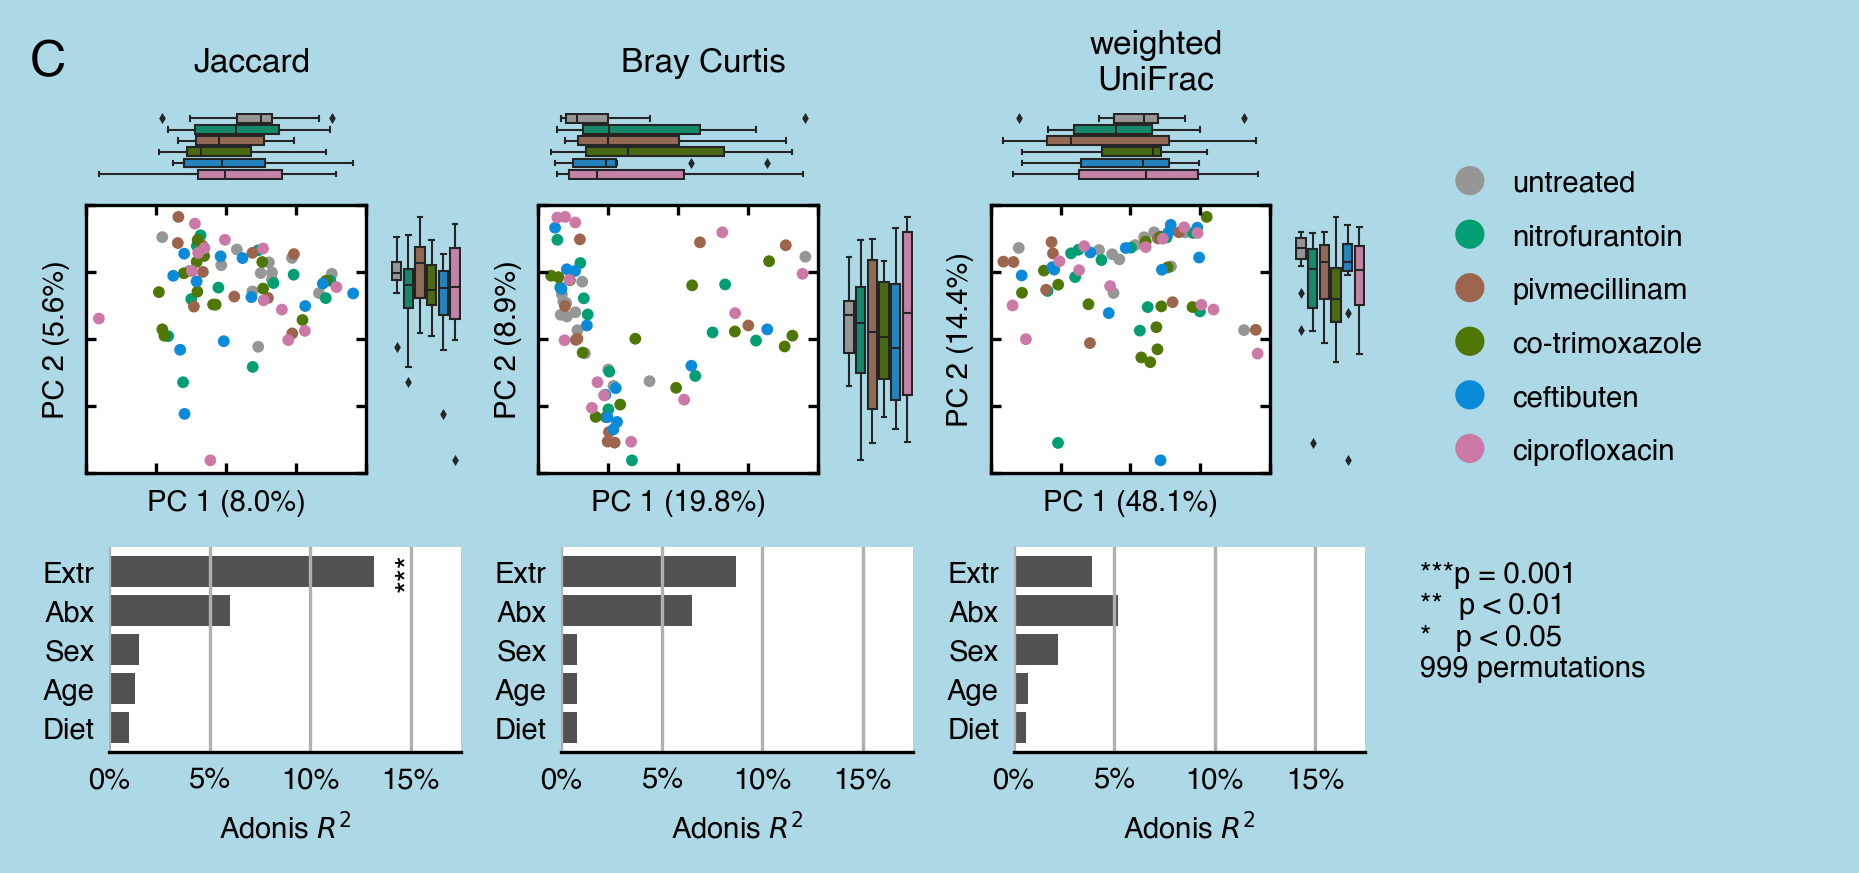

In [19]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(6, 2.75), facecolor='lightblue')
def _build_beta_panels(fig):
    """
    Convenience function to mak the beta figure easier
    """
    figs = fig.subfigures(3, 4, height_ratios=[0.15, 1, 0.75], facecolor='None')
    for fig_r, met_info in zip(*(figs.T, met_order)):
        _plot_baseline_pc(*fig_r, *met_info)
    axl = figs.T[-1][1].add_subplot(1,1,1, facecolor='None')
    axl.scatter(y=5 - np.arange(0, 6), 
                x=np.ones(6),
                c=colors,
                marker='o',
               )
    axl.set_ylim(-0.5, 5.5)
    axl.set_yticks(5 - np.arange(0, 6))
    axl.set_yticklabels(abx_order)
    axl.xaxis.set_tick_params(**hide_axes)
    axl.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=True, labelsize=7, length=0)
    axl.set_position((0.125, 0.125, 0.125, 0.75))
    sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)
    
    axa = figs.T[-1][2].add_subplot(1,1,1, facecolor='None')
    axa.set_xlim(0, 1)
    axa.set_ylim(0, 1)
    axa.text(s='***p = 0.001\n**  p < 0.01\n*   p < 0.05\n999 permutations',
             x=0.05, y=0.95, ha='left', va='top', size=7)
    axa.xaxis.set_tick_params(**hide_axes)
    axa.yaxis.set_tick_params(**hide_axes)
    sn.despine(ax=axa, left=True, right=True, top=True, bottom=True)
    figs[0][0].axes[0].text(figs[0][0].axes[0].get_xlim()[0],
                            np.mean(figs[0][0].axes[0].get_ylim()),
                            'C', size=12, ha='left', va='center')
    
_build_beta_panels(fig)

## Alpha Diversity

In [20]:
meta_a = pd.concat(axis=1, objs=[meta_bl, alpha_bl])
meta_a['age'] = meta_a['age'].astype(float)

In [21]:
def _anova_res_wrap(metric, fit_):
    """
    Pulls out the anova results for the baseline OLS
    """
    anova = sms.stats.anova_lm(fit_)
    anova['n_obs'] = fit_.nobs
    anova['p'] = anova['df'] + 1
    anova['r2'] = anova['sum_sq'] / anova['sum_sq'].sum()
    anova['metric'] = metric
    
    return anova

In [22]:
alpha_bl_fit = {
    metric: smf.ols(f'{metric} ~ abx_code2 + extraction_no + sex + age + vegetarian',
                    data=meta_a).fit()
    for metric in ['z_obs_feat', 'shannon', 'simpson']
}

In [23]:
alpha_anova_res = pd.concat(
    axis=0, 
    objs=[_anova_res_wrap(metric, fit_) 
          for metric, fit_ in alpha_bl_fit.items()]
)
alpha_anova_res.drop(['Residual'], inplace=True)
alpha_anova_res.set_index('metric', append=True, inplace=True)
alpha_anova_res.sort_values('r2', ascending=False, inplace=True)
alpha_anova_res

df    sum_sq   mean_sq         F    PR(>F)  n_obs  \
              metric                                                           
extraction_no z_obs_feat  6.0  8.016629  1.336105  1.299438  0.271973   73.0   
              simpson     6.0  0.020442  0.003407  0.775892  0.592054   74.0   
              shannon     6.0  2.317955  0.386326  0.663740  0.679073   74.0   
abx_code2     z_obs_feat  5.0  3.185799  0.637160  0.619674  0.685280   73.0   
              simpson     5.0  0.005712  0.001142  0.260146  0.932971   74.0   
vegetarian    shannon     1.0  0.518688  0.518688  0.891149  0.349016   74.0   
              z_obs_feat  1.0  0.980787  0.980787  0.953871  0.332792   73.0   
abx_code2     shannon     5.0  0.493983  0.098797  0.169741  0.972783   74.0   
sex           simpson     1.0  0.003379  0.003379  0.769633  0.383889   74.0   
vegetarian    simpson     1.0  0.002098  0.002098  0.477680  0.492186   74.0   
sex           shannon     1.0  0.181478  0.181478  0.311795  0.578694   74.0   
age           shannon     1.0  0.114706  0.114706  0.197075  0.658716   74.0   
              z_obs_feat  1.0  0.146391  0.146391  0.142374  0.707310   73.0   
              simpson     1.0  0.000362  0.000362  0.082526  0.774909   74.0   
sex           z_obs_feat  1.0  0.033762  0.033762  0.032836  0.856837   73.0   

                            p        r2  
              metric                     
extraction_no z_obs_feat  7.0  0.111342  
              simpson     7.0  0.070231  
              shannon     7.0  0.061051  
abx_code2     z_obs_feat  6.0  0.044247  
              simpson     6.0  0.019623  
vegetarian    shannon     2.0  0.013661  
              z_obs_feat  2.0  0.013622  
abx_code2     shannon     6.0  0.013011  
sex           simpson     2.0  0.011611  
vegetarian    simpson     2.0  0.007206  
sex           shannon     2.0  0.004780  
age           shannon     2.0  0.003021  
              z_obs_feat  2.0  0.002033  
              simpson     2.0  0.001245  
sex           z_obs_feat  2.0  0.000469

(-0.75, 5.75)

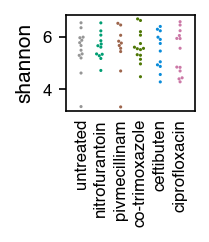

In [24]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 1.5))
gs = fig.add_gridspec(1, 3)
ax0 = fig.add_subplot(gs[0])
ax0.xaxis.set_tick_params(bottom=False, 
                          labelbottom=True, 
                          labelsize=8,
                          top=False, 
                          labeltop=False, 
                          length=0)
ax0.yaxis.set_tick_params(left=True, labelleft=True, 
                          right=False, labelright=False, 
                          labelsize=8)
sn.swarmplot(ax=ax0, 
           x='abx_code2', 
           y='shannon', 
           data=meta_a,
           order=['0', '1', '2', '3', '4', '5'],
           palette=abx_colors,
            s=1.5,
           )
ax0.set_xticks(np.arange(6))
ax0.set_xticklabels(abx_order, rotation=90)
ax0.xaxis.get_label().set_visible(False)

ax0.set_xlim(-0.75, 5.75)

In [25]:
var_order = ['extraction_no', 'abx_code2', 'vegetarian', 'age', 'sex']

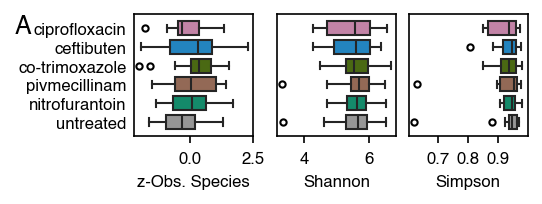

In [26]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3.5, 1.25))
def _plot_alpha_boxplot(fig):
    """
    A helper function to wrap panel plotting
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax)
        sn.boxplot(ax=ax, 
                   orient='h',
                   x=metric, 
                   y='abx_code2', 
                   data=meta_a,
                   order=['0', '1', '2', '3', '4', '5'],
                   palette=abx_colors,
                   width=0.75,
                   linewidth=1,
                   flierprops=dict(markersize=3, 
                                   markerfacecolor='None', 
                                   markeredgecolor='k',
                                   marker='o')
                   )
        ax.set_yticks(np.arange(6))
        ax.set_yticklabels(abx_order)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, length=0, labelsize=8)
        ax.yaxis.get_label().set_visible(False)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, labelsize=8)
        ax.set_ylim(-0.75, 5.75)
    fig.axes[0].set_xlabel('z-Obs. Species', size=8)
    fig.axes[1].set_xlabel('Shannon', size=8)
    fig.axes[2].set_xlabel('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 1,
                     fig.axes[0].get_ylim()[1],
                     'A',
                     size=12, ha='left', va='top')
_plot_alpha_boxplot(fig)

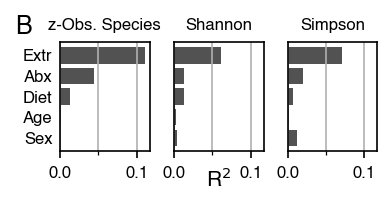

In [27]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(2.5, 1.25))
def _plot_r2_alpha(fig):
    """
    A wrapper function for alpha diveristy correlations?
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax, sharex=ax)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, labelsize=8, length=0)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, top=False, 
                                 labeltop=False, labelsize=8)
        ax.barh(y=4 - np.arange(5),
               left=0,
               width=alpha_anova_res.xs(metric, level='metric').loc[var_order, 'r2'],
                color='#525252',
               )
        ax.set_yticks(4 - np.arange(5))
        ax.set_yticklabels(['Extr', 'Abx', 'Diet', 'Age', 'Sex'])
        if i == 1:
            ax.text(x=np.mean(ax.get_xlim()),
                    y=ax.get_ylim()[0] - np.diff(ax.get_ylim()) * 0.15,
                    s='R$^{2}$', 
                    ha='center', 
                    va='top',
                    size=10)
        ax.set_xticks(np.arange(0, 0.11, 0.05), minor=True)
        ax.xaxis.grid(True, which='both')
    fig.axes[0].set_title('z-Obs. Species', size=8)
    fig.axes[1].set_title('Shannon', size=8)
    fig.axes[2].set_title('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.5,
                     fig.axes[0].get_ylim()[1] + np.diff(fig.axes[0].get_ylim()) * 0.25,
                     'B', size=12, ha='left', va='top')
_plot_r2_alpha(fig)

# Differential Abundance

In [28]:
table_bl_q2 = Artifact.load('final-data/05.rpca/baseline_rpca/filt_table.qza')
taxa_q2 = Artifact.load('final-data/02.tables/matched-taxonomy-gtdb.qza')
species_bl_q2, = q2_taxa.collapse(table_bl_q2, taxa_q2, level=7)
os.makedirs('final-data/06.baseline_compare', exist_ok=True)
species_bl = species_bl_q2.view(pd.DataFrame).T
species_bl['labels'] = species_bl.index
species_bl.to_csv('final-data/06.baseline_compare/filtered-species-bl.tsv',
                  sep='\t')

In [29]:
%%bash
Rscript scripts/taxa-baseline/ancom-baseline-taxa.r

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: foreach

Attaching package: ‘foreach’

The following objects are masked from ‘package:purrr’:

    accumulate, when

Loading required package: rngtools


In [30]:
taxa_bl_res = pd.read_csv('final-data/06.baseline_compare/antibiotic-taxa-ancombc-res.tsv',
                         sep='\t',
                         dtype=str)
taxa_bl_res.set_index('taxon', inplace=True)
taxa_bl_res.replace({"FALSE": '0', 'TRUE': '1'}, inplace=True)
taxa_bl_res = taxa_bl_res.astype(float).T
taxa_bl_resl = taxa_bl_res.reset_index().melt(id_vars='index')
taxa_bl_resl['abx'] = taxa_bl_resl['index'].apply(lambda x: x[-1])
taxa_bl_resl['stat'] = taxa_bl_resl.apply(
    lambda x: x['index'].replace(x['abx'], '').replace('_abx_code2', ''), 
    axis=1)
taxa_bl_resl.replace({'abx': {'B': '1', 'C': '2', 'D': '3', 'E': '4', 'F': '5'}},
                    inplace=True)
taxa_bl_resw = taxa_bl_resl.pivot(index=['abx', 'taxon'], 
                                columns='stat',
                                values='value')
taxa_bl_resw['log_q'] = -np.log10(taxa_bl_resw['q'])
taxa_bl_resw['log_q'] = taxa_bl_resw['log_q'].mask(taxa_bl_resw['log_q'] <= 0, 0)

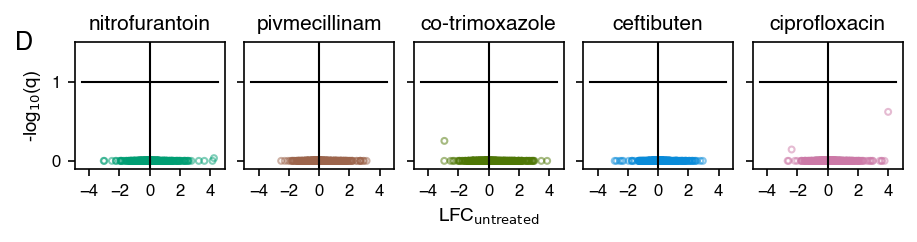

In [31]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 1.5))
def _ancom_bc_plot(fig):
    """
    Builds ANCOM-BC scatter plot
    """
    gs = fig.add_gridspec(1, 5)
    
    for i, (abx, df) in enumerate(taxa_bl_resw.groupby('abx', sort=True)):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharex=ax, sharey=ax)
        ax.scatter(x='lfc', y='log_q', data=df,
                   marker='o',
                   s=8,
                   alpha=0.5,
                   color=abx_colors[abx],
                   facecolor='None',
                  )
        ax.set_ylim(-0.1, 1.5)
        ax.plot([0, 0], ax.get_ylim(), color='k', linewidth=1)
        ax.plot([-4.5, 4.5], [1, 1], color='k', linewidth=1)
        ax.yaxis.set_tick_params(left=True, labelleft=(i == 0), 
                                 right=False, labelright=False, 
                                 labelsize=8)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True,
                                 labeltop=False, top=False,
                                 labelsize=8)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.set_xlabel('LFC$_{\\mathrm{untreated}}$', size=9)
        ax.set_ylabel('-log$_{10}$(q)', size=9)
        ax.set_title(abx_order[i + 1], size=10)
        
        ax.yaxis.get_label().set_visible(i == 0)
        ax.xaxis.get_label().set_visible(i == 2)
        ax.xaxis.set_tick_params(labelsize=8)
        ax.yaxis.set_tick_params(labelsize=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.4,
                     fig.axes[0].get_ylim()[1],
                     'D', ha='left', va='center', size=12)
_ancom_bc_plot(fig)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


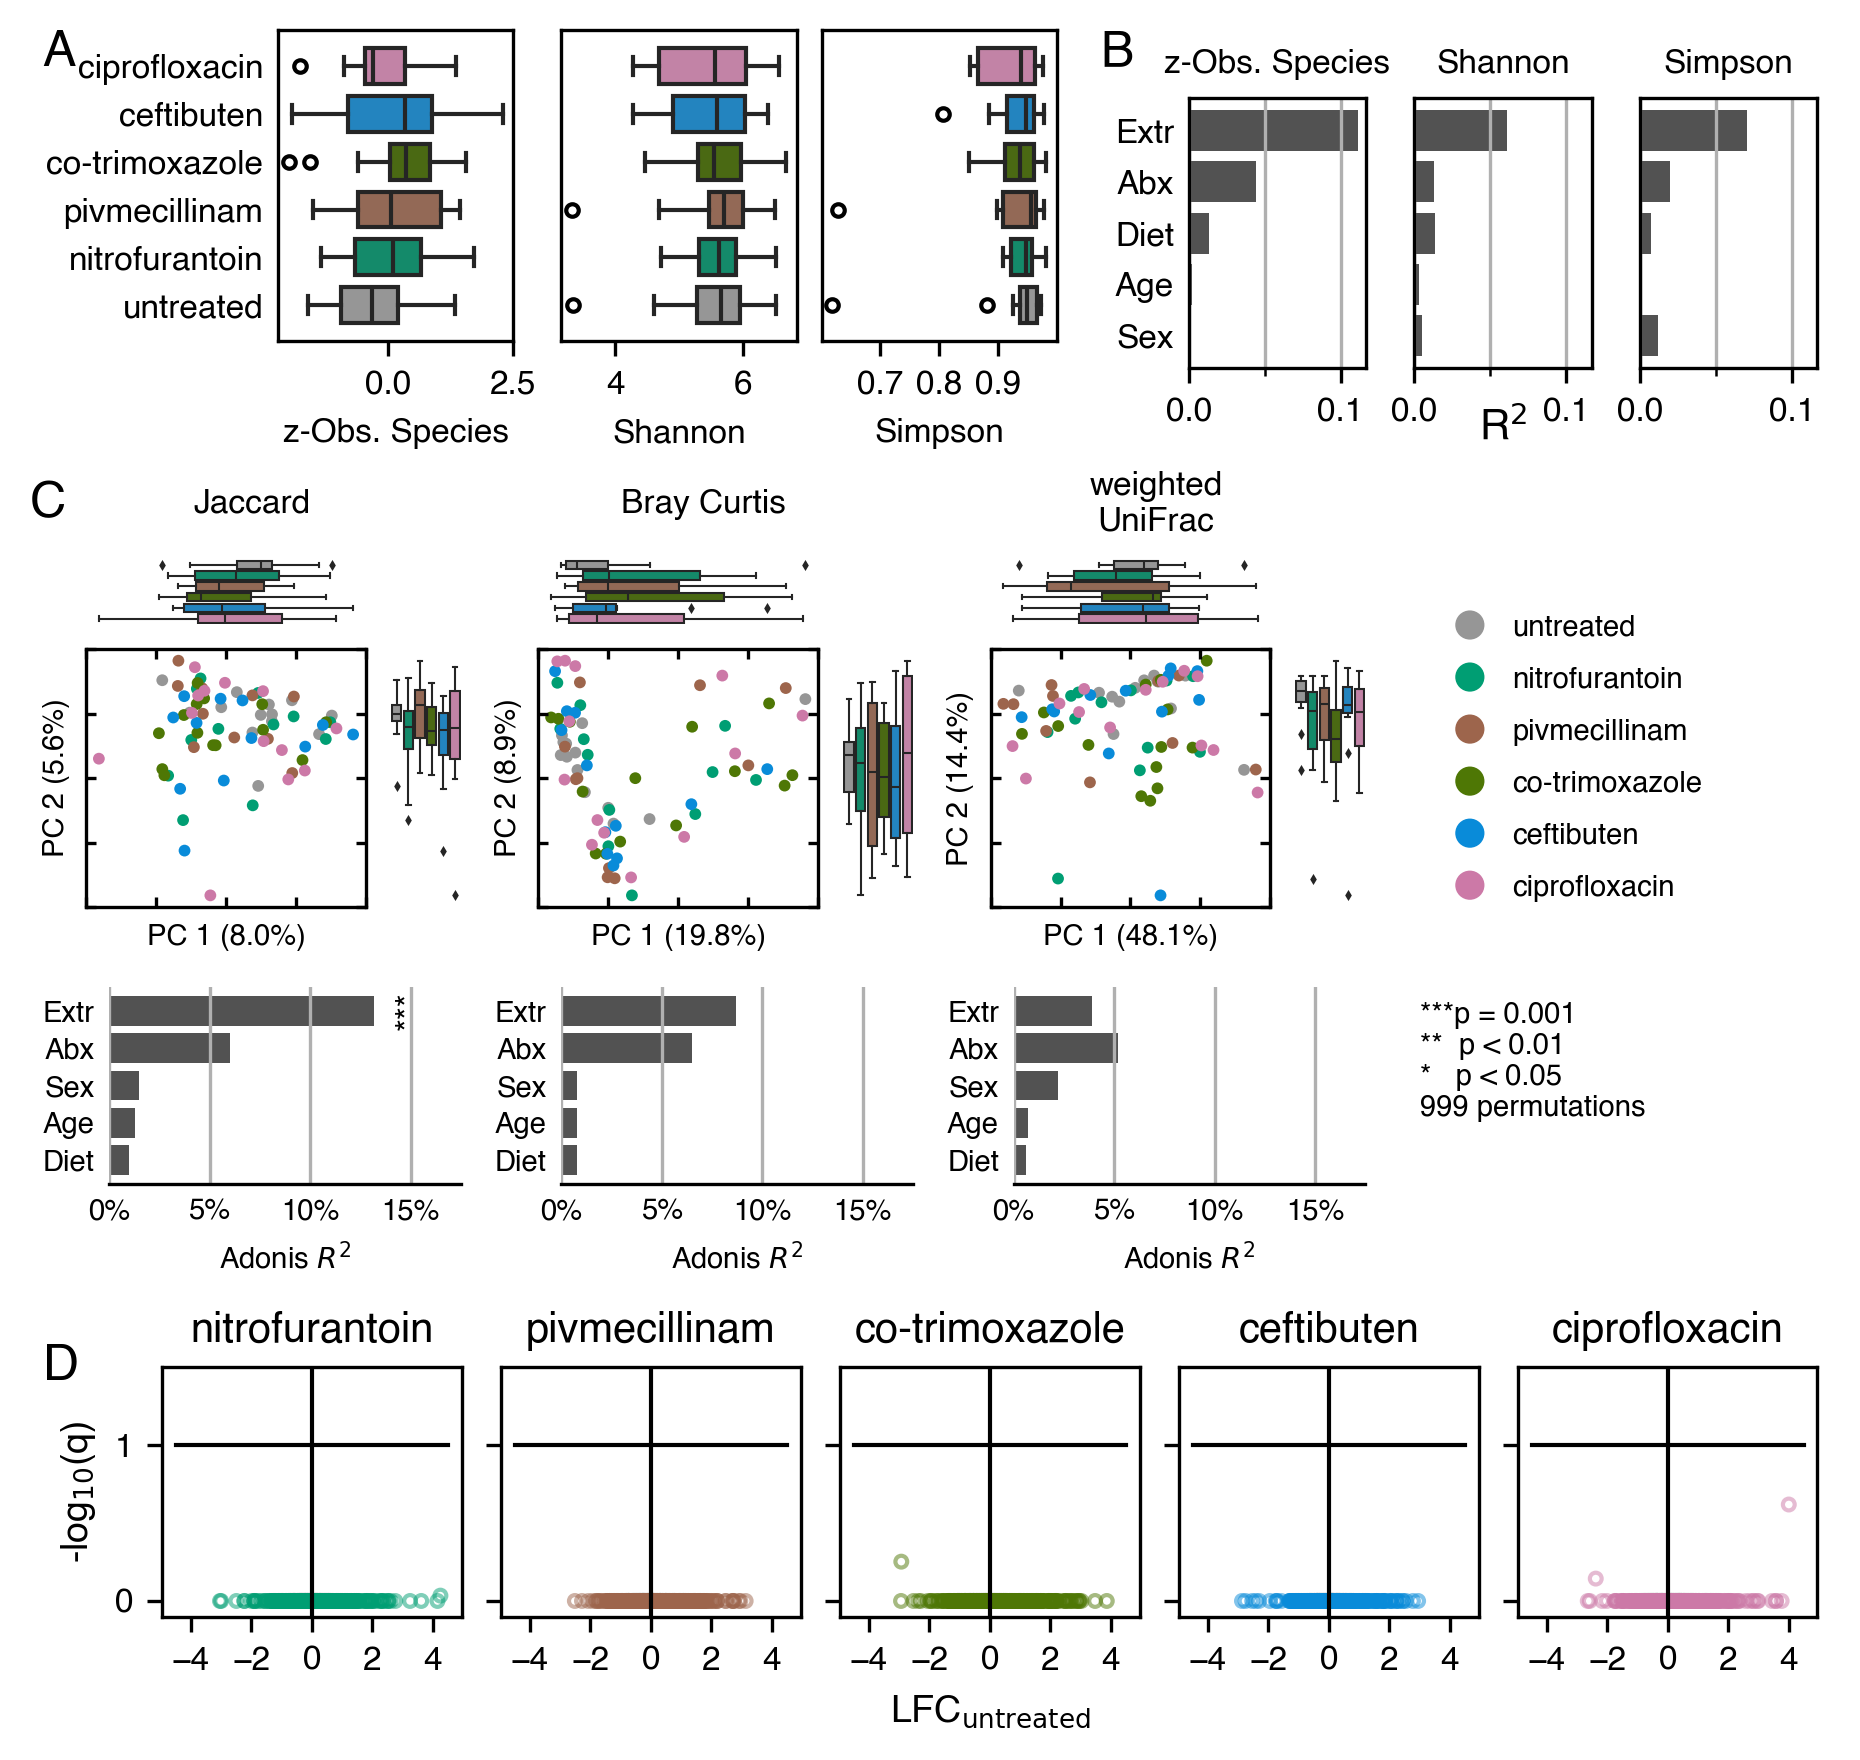

In [32]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(6, 5.75), facecolor='None')
[figa, figb, figda] = fig.subfigures(3, 1, height_ratios=[1.5, 2.75, 1.5], facecolor='None')
figaa, figab = figa.subfigures(1, 2, width_ratios=[3.5, 2.5], facecolor='None')
_plot_alpha_boxplot(figaa)
_plot_r2_alpha(figab)
_build_beta_panels(figb)
_ancom_bc_plot(figda)
fig.savefig('output/figures/figure_s2_taxa_baseline.png', dpi=300, facecolor='None')
fig.savefig('output/figures/figure_s2_taxa_baseline.pdf', dpi=300, facecolor='None')


**Figure S2. Taxonomic microbiome composition at baseline.** There is no difference in alpha diversity (A,B) between treatment allocation groups at baseline. (A) Boxplots show the distribution of (left to right) z-normalized Observed Species, Shannon Diversity, and Simpson Diversity. (B) Variance explained by alpha diversity at baseline by extraction plate (Extr), treatment allocation (abx), vegetarian diet (diet), participant age, and participant sex. No difference was statically significant. (C) There were no differences in beta diveristy at baseline between treatment groups. The top row shows ordiation projections colored by treatment group for (left to right) Jaccard distance, unweighted UniFrac distance, phylogenetic rPCA, Bray Curtis dissimilarity, and weighted UniFrac distance. The bottom row shoes the variance explained at baseline by extraction plate (Extr), treatment allocation (abx), vegetarian diet (diet), participant age, and participant sex. Variance as calculated with an adonis model with the variable of interest last; adonis was run with 999 permutations. (D) Volcano plot of ANCOM-BC based differential abundance at baseline. The horizonal line indicates an FDR corrected p-value of 0.1.

